In [2]:
import math
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

In [174]:
class Value():
    def __init__(self, data, prev=(), op='', label=''):
        self.data = data
        self.prev = set(prev)
        self.grad = None
        self.op = op
        self.label = label
        self.grad = 0
        self._backward = lambda : None

    def __repr__(self):
        return "Value(data=%s)" % self.data

    def __add__(self, node):
        node = node if isinstance(node, Value) else Value(node)
        result_data = self.data + node.data
        result = Value(result_data, (self, node), op='+')

        def _backward():
            self.grad += result.grad * 1.0
            node.grad += result.grad * 1.0

        result._backward = _backward
        return result

    def __radd__(self, node):
        return self + node

    def __sub__(self, node):
        return self + (-1 * node)

    def __rsub__(self, node):
        return self - node

    def __mul__(self, node):
        node = node if isinstance(node, Value) else Value(node)
        result_data = self.data * node.data
        result = Value(result_data, (self, node), op='*')

        def _backward():
            self.grad += result.grad * node.data
            node.grad += result.grad * self.data

        result._backward = _backward
        return result

    def __rmul__(self, node):
        return self * node

    def __pow__(self, exp):
        result_data = self.data**exp
        result = Value(result_data, (self,), op='**')

        def _backward():
            self.grad += exp * (self.data**(exp-1)) * result.grad

        result._backward = _backward
        return result

    def tanh(self):
        result_data = (math.exp(2*self.data) - 1) / (math.exp(2*self.data) + 1)
        result = Value(result_data, (self,), 'tanh')

        def _backward():
            self.grad += (1 - pow(result_data, 2)) * result.grad

        result._backward = _backward
        return result

    def backward(self):
        topo = []
        visited = set()

        def build_topo(v):
            if v not in visited:
                visited.add(v)
                
                for node in v.prev:
                    build_topo(node)

                topo.append(v)

        build_topo(self)
        self.grad = 1.0

        for node in reversed(topo):
            node._backward()

Value(2)**2

Value(data=4)

In [42]:
from graphviz import Digraph

def trace(root):
  # builds a set of all nodes and edges in a graph
  nodes, edges = set(), set()
  def build(v):
    if v not in nodes:
      nodes.add(v)
      for child in v.prev:
        edges.add((child, v))
        build(child)
  build(root)
  return nodes, edges

def draw_dot(root):
  dot = Digraph(format='svg', graph_attr={'rankdir': 'LR'}) # LR = left to right
  
  nodes, edges = trace(root)
  for n in nodes:
    uid = str(id(n))
    # for any value in the graph, create a rectangular ('record') node for it
    dot.node(name = uid, label = "{ %s | data %.4f | grad %.4f }" % (n.label, n.data, n.grad), shape='record')
    if n.op:
      # if this value is a result of some operation, create an op node for it
      dot.node(name = uid + n.op, label = n.op)
      # and connect this node to it
      dot.edge(uid + n.op, uid)

  for n1, n2 in edges:
    # connect n1 to the op node of n2
    dot.edge(str(id(n1)), str(id(n2)) + n2.op)

  return dot

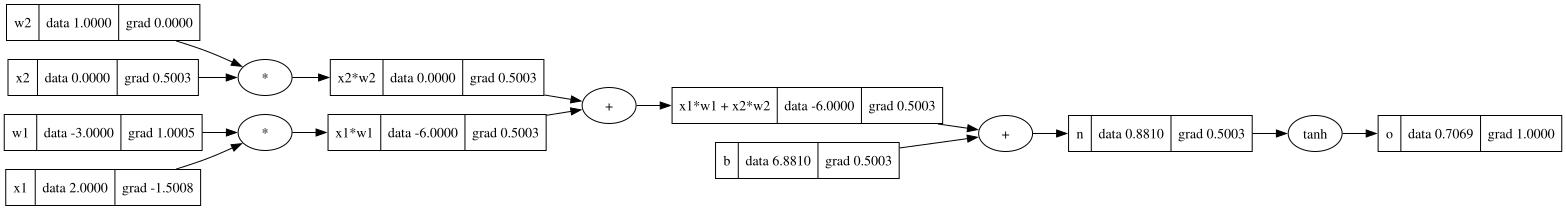

In [46]:
draw_dot(o)

In [44]:
# inputs
x1 = Value(2.0, label='x1')
x2 = Value(0.0, label='x2')
# weights
w1 = Value(-3.0, label='w1')
w2 = Value(1.0, label='w2')
# bias
b = Value(6.881, label='b')

x1w1 = x1*w1; x1w1.label = 'x1*w1'
x2w2 = x2*w2; x2w2.label = 'x2*w2'
x1w1x2w2 = x1w1 + x2w2; x1w1x2w2.label = 'x1*w1 + x2*w2'
n = x1w1x2w2 + b; n.label='n'
o = n.tanh(); o.label = 'o'

In [45]:
o.backward()

In [47]:
import torch

In [55]:
x1 = torch.Tensor([2.0]).double(); x1.requires_grad = True
x2 = torch.Tensor([0.0]).double(); x2.requires_grad = True
w1 = torch.Tensor([-3.0]).double(); w1.requires_grad = True
w2 = torch.Tensor([1.0]).double(); w2.requires_grad = True
b = torch.Tensor([6.881]).double(); b.requires_grad = True
n = x1*w1 + x2*w2 + b
o = torch.tanh(n)

o

tensor([0.7069], dtype=torch.float64, grad_fn=<TanhBackward0>)

In [56]:
o.backward()

In [60]:
x1.grad

tensor([-1.5008], dtype=torch.float64)

In [234]:
import random

class Neuron():
    def __init__(self, nin):
        self.weights = [Value(random.uniform(-1, 1)) for _ in range(nin)]
        self.bias = Value(random.uniform(-1, 1))

    def __call__(self, inputs):
        act = sum([self.weights[i] * inputs[i] for i in range(len(self.weights))], start=self.bias)
        out = act.tanh()
        return out

    def parameters(self):
        return self.weights + [self.bias]

class Layer():
    def __init__(self, nin, nout):
        self.neurons = [Neuron(nin) for _ in range(nout)]

    def __call__(self, inputs):
        return [neuron(inputs) for neuron in self.neurons]

    def parameters(self):
        params = []

        for neuron in self.neurons:
            params.extend(neuron.parameters())
            
        return params

class MLP():
    def __init__(self, nin, nouts):
        sizes = [nin] + nouts
        self.layers = [Layer(sizes[i], sizes[i+1]) for i in range(len(sizes)-1)]

    def __call__(self, inputs):
        x = inputs
        
        for layer in self.layers:
            x = layer(x)

        return x[0] if len(x) == 1 else x

    def parameters(self):
        params = []

        for layer in self.layers:
            params.extend(layer.parameters())

        return params

x = [2.0, 3.0, -1.0]
mlp = MLP(3, [4, 4, 1])
mlp(x)

Value(data=-0.38044754982908946)

In [235]:
mlp.parameters()

[Value(data=-0.8223543196220053),
 Value(data=0.322520946714681),
 Value(data=-0.4819070149890896),
 Value(data=0.07542950242089597),
 Value(data=-0.07931872554641406),
 Value(data=-0.7827542072688176),
 Value(data=-0.47120654326909417),
 Value(data=-0.9565548643560371),
 Value(data=-0.10637270298109813),
 Value(data=0.24939656940095434),
 Value(data=0.7211253043365209),
 Value(data=0.4895805915089684),
 Value(data=-0.02922805514892901),
 Value(data=0.18466580425132828),
 Value(data=-0.7124228871728375),
 Value(data=0.39378194385110565),
 Value(data=-0.15358345661186212),
 Value(data=0.9757432451681667),
 Value(data=0.5397753802955343),
 Value(data=0.9802417998770108),
 Value(data=0.29877466138179565),
 Value(data=-0.6112025690818699),
 Value(data=0.19803268615478786),
 Value(data=-0.03591640683519781),
 Value(data=0.7345187332191441),
 Value(data=-0.08484404132159229),
 Value(data=0.6519335959015891),
 Value(data=-0.307590961454681),
 Value(data=-0.12290248029700757),
 Value(data=0.73

In [236]:
xs = [
    [2.0, 3.0, -1.0],
    [3.0, -1.0, 0.5],
    [0.5, 1.0, 1.0],
    [1.0, 1.0, -1.0]
]
ys = [1.0, -1.0, -1.0, 1.0]

In [237]:
def train(mlp, learning_rate=0.1, epochs=50):
    for i in range(epochs):
        y_preds = [mlp(x) for x in xs]
        loss = sum([(y - y_pred)**2 for y, y_pred in zip(ys, y_preds)])
    
        print("%s: %s" % (i, loss))
    
        for param in mlp.parameters():
            param.grad = 0
    
        loss.backward()
        
        for param in mlp.parameters():
            param.data += -1*learning_rate * param.grad

In [238]:
train(mlp)

0: Value(data=3.918853218969349)
1: Value(data=2.382152230968241)
2: Value(data=4.193386571196106)
3: Value(data=0.9015269656994096)
4: Value(data=0.08641586151588448)
5: Value(data=0.06131242552356268)
6: Value(data=0.047764189985239555)
7: Value(data=0.039208668242432076)
8: Value(data=0.03329375977112307)
9: Value(data=0.028952533174907306)
10: Value(data=0.025627359037015914)
11: Value(data=0.022997307640336234)
12: Value(data=0.020864202739447328)
13: Value(data=0.019098887003193947)
14: Value(data=0.01761350684857084)
15: Value(data=0.01634618741869168)
16: Value(data=0.015252072329874695)
17: Value(data=0.014297838944324988)
18: Value(data=0.01345820959389837)
19: Value(data=0.012713658672466502)
20: Value(data=0.012048862620942034)
21: Value(data=0.011451626066129662)
22: Value(data=0.010912121599412445)
23: Value(data=0.010422341183797527)
24: Value(data=0.009975693445986682)
25: Value(data=0.00956670347803405)
26: Value(data=0.009190785922560948)
27: Value(data=0.008844071272

In [239]:
y_preds

[Value(data=0.9935515243695662),
 Value(data=-0.9964473875680956),
 Value(data=-0.9779508729161903),
 Value(data=0.9866587334625253)]